In [ ]:
# To merge i created this file with all tests

# Chemical simulation interface
This notebook provides an interface for a toy model of a chemical reaction in the gas phase.

## Import libraries

In [ ]:
# %pip install -r requirements.txt

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from collider import Simulation
from ipycanvas import Canvas

In [3]:
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import time

In [4]:
from collider import Simulation
from ipycanvas import Canvas, hold_canvas
import ipywidgets as widgets
from IPython.display import display
import time

## Initialize and run the simulation
Initialize the Simulation class with the desired parameters and run the simulation loop.

In [5]:
simulation = Simulation(Canvas, 800, 600, 100, temperature=100)
# simulation.canvas
chart_canvas = Canvas(width=400, height=600)

# Display the simulation canvas and the chart canvas side-by-side
display(widgets.HBox([simulation.canvas, chart_canvas]))


In [ ]:
simulation.run()

In [6]:
# Run this instead of simulation.run() => First live-updating chart appended above

max_points = 300  # Number of recent frames visible on the chart

while True:
    # 1. Advance the simulation by one step
    simulation.update()
    simulation.draw()
    
    # 2. Take the latest collision counts from simulation.collision_history
    data = simulation.collision_history[-max_points:]
    
    # 3. Draw the live chart onto chart_canvas
    with hold_canvas(chart_canvas):
        chart_canvas.clear()
        
        # Draw X and Y axes
        chart_canvas.stroke_style = "black"
        chart_canvas.line_width = 1
        chart_canvas.stroke_line(50, 40, 50, 550)   # Y-axis
        chart_canvas.stroke_line(50, 550, 380, 550) # X-axis

        # --- ADD AXIS TITLES HERE ---
        chart_canvas.fill_style = "black"
        chart_canvas.font = "14px sans-serif"

        # X-axis title (centered below the X-axis)
        chart_canvas.fill_text("Simulation Steps", 165, 585)

        # Y-axis title (rotated vertically to the left of the Y-axis)
        chart_canvas.save()
        chart_canvas.translate(20, 330)
        chart_canvas.rotate(-1.5708)  # -90 degrees in radians (-pi / 2)
        chart_canvas.fill_text("Collision Count", 0, 0)
        chart_canvas.restore()
        # ----------------------------
        
        # Display current count as text
        chart_canvas.fill_style = "black"
        chart_canvas.font = "16px sans-serif"
        chart_canvas.fill_text(f"Collisions: {simulation.collision_count}", 60, 30)
        
        # Plot the line graph
        if len(data) > 1:
            min_y = min(data)
            max_y = max(data)
            y_range = (max_y - min_y) if max_y > min_y else 1
            
            chart_canvas.stroke_style = "blue"
            chart_canvas.line_width = 2
            chart_canvas.begin_path()
            
            for i, value in enumerate(data):
                px = 50 + (i / max_points) * 330
                py = 550 - ((value - min_y) / y_range) * 490
                if i == 0:
                    chart_canvas.move_to(px, py)
                else:
                    chart_canvas.line_to(px, py)
            chart_canvas.stroke()
            
    time.sleep(0.002)

KeyboardInterrupt: 

In [7]:
print(simulation.get_current_metrics())

{'collisions': 8728468}


In [9]:
# Final version with live-updating chart with collision count

from collider import Simulation
from ipycanvas import Canvas, hold_canvas
from ipywidgets import VBox
import time

# 1. Initialize simulation and separate chart canvas
simulation = Simulation(Canvas, 800, 600, 100, temperature=100)
chart_canvas = Canvas(width=800, height=250)

# Display both canvases together
display(VBox([simulation.canvas, chart_canvas]))

max_points = 300
step = 0

while True:
    # 2. Step simulation and draw particles
    simulation.update()
    simulation.draw()
    
    # 3. Update chart every 5 steps to keep animation completely lag-free
    if step % 5 == 0:
        data = simulation.collision_history[-max_points:]
        
        with hold_canvas(chart_canvas):
            chart_canvas.clear()
            
            # Axes
            chart_canvas.stroke_style = "black"
            chart_canvas.line_width = 1
            chart_canvas.stroke_line(60, 20, 60, 210)   # Y-axis
            chart_canvas.stroke_line(60, 210, 770, 210) # X-axis
            
            # Title & Axis Labels
            chart_canvas.fill_style = "black"
            chart_canvas.font = "14px sans-serif"
            chart_canvas.fill_text(f"Collision Count: {simulation.collision_count}", 70, 25)
            chart_canvas.fill_text("Simulation Steps", 370, 240)
            
            chart_canvas.save()
            chart_canvas.translate(20, 150)
            chart_canvas.rotate(-1.5708)
            chart_canvas.fill_text("Collisions", 0, 0)
            chart_canvas.restore()
            
            # Line plot
            if len(data) > 1:
                min_y = min(data)
                max_y = max(data)
                y_range = (max_y - min_y) if max_y > min_y else 1
                
                chart_canvas.stroke_style = "blue"
                chart_canvas.line_width = 2
                chart_canvas.begin_path()
                
                for i, val in enumerate(data):
                    px = 60 + (i / max_points) * 710
                    py = 210 - ((val - min_y) / y_range) * 180
                    if i == 0:
                        chart_canvas.move_to(px, py)
                    else:
                        chart_canvas.line_to(px, py)
                chart_canvas.stroke()
                
    step += 1
    time.sleep(0.002)

KeyboardInterrupt: 

KeyboardInterrupt: 

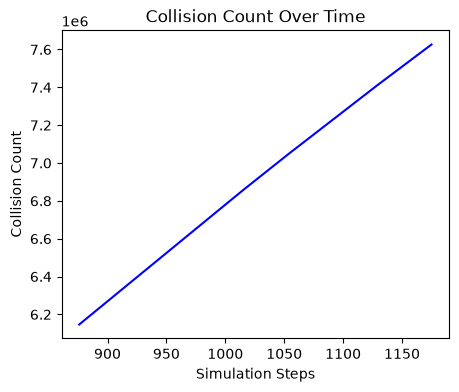

In [10]:
# Lagging but works theoretically

import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
from ipycanvas import Canvas
from collider import Simulation
import time

# 1. Initialize simulation
simulation = Simulation(Canvas, 600, 500, 100, temperature=100)

# 2. Create widgets and arrange layout
status_label = widgets.Label(value="Collisions: 0")
chart_output = widgets.Output()

right_panel = widgets.VBox([status_label, chart_output])
display(widgets.HBox([simulation.canvas, right_panel]))

# 3. Set up Matplotlib figure
plt.ioff()
fig, ax = plt.subplots(figsize=(5, 4))
steps = []
collisions = []

# 4. Run simulation loop
step = 0
while True:
    simulation.update()
    simulation.draw()
    
    status_label.value = f"Collisions: {simulation.collision_count}"
    
    steps.append(step)
    collisions.append(simulation.collision_count)
    
    if step % 25 == 0:
        with chart_output:
            clear_output(wait=True)
            ax.clear()
            ax.plot(steps[-300:], collisions[-300:], color="blue")
            ax.set_title("Collision Count Over Time")
            ax.set_xlabel("Simulation Steps")
            ax.set_ylabel("Collision Count")
            display(fig)
            
    step += 1
    time.sleep(0.002)

KeyboardInterrupt: 

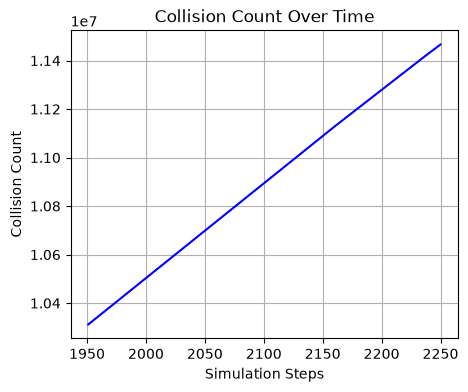

In [ ]:
# import ipywidgets as widgets
# from IPython.display import display, clear_output
# import matplotlib.pyplot as plt
# from ipycanvas import Canvas
# from collider import Simulation
# import time

# # 1. Initialize simulation
# simulation = Simulation(Canvas, 600, 500, 100, temperature=100)

# # 2. Create widgets for live text readout and chart output
# status_label = widgets.Label(value="Collisions: 0")
# chart_output = widgets.Output()

# # Arrange simulation canvas on the left, label + chart on the right
# right_panel = widgets.VBox([status_label, chart_output])
# display(widgets.HBox([simulation.canvas, right_panel]))

# # 3. Set up Matplotlib figure once
# plt.ioff()
# fig, ax = plt.subplots(figsize=(5, 4))
# steps = []
# collisions = []

# step = 0
# while True:
#     simulation.update()
#     simulation.draw()
    
#     # Update live text widget every frame (instant, zero lag)
#     status_label.value = f"Collisions: {simulation.collision_count}"
    
#     steps.append(step)
#     collisions.append(simulation.collision_count)
    
#     # Update Matplotlib chart inside the Output widget every 25 steps
#     if step % 25 == 0:
#         with chart_output:
#             clear_output(wait=True)
#             ax.clear()
#             ax.plot(steps[-300:], collisions[-300:], color="blue")
#             ax.set_title("Collision Count Over Time")
#             ax.set_xlabel("Simulation Steps")
#             ax.set_ylabel("Collision Count")
#             ax.grid(True)
#             display(fig)
            
#     step += 1
#     time.sleep(0.002)

Simulation stopped by user.


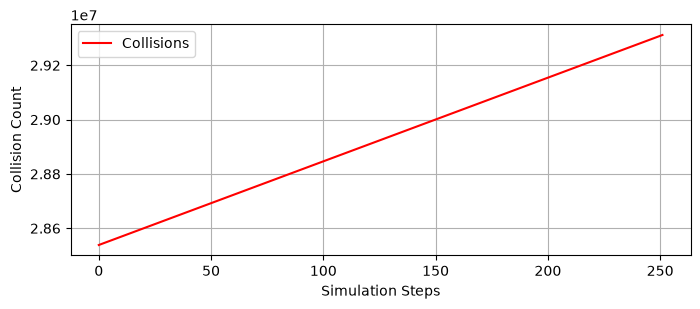

In [ ]:
# # Enable interactive mode for real-time plotting
# plt.ion()

# steps = []
# collision_data = []

# # Create the live plot window
# fig, ax = plt.subplots(figsize=(8, 3))
# line, = ax.plot([], [], 'r-', label="Collisions")
# ax.set_xlabel("Simulation Steps")
# ax.set_ylabel("Collision Count")
# ax.legend()
# ax.grid(True)

# step = 0

# try:
#     # Infinite loop to run the simulation and update the live graph
#     while True:
#         # 1. Update and draw the simulation step-by-step
#         simulation.update()
#         simulation.draw()
        
#         # 2. Fetch current metrics from the simulation orchestrator
#         metrics = simulation.get_current_metrics()
#         steps.append(step)
#         collision_data.append(metrics["collisions"])
        
#         # 3. Keep only the last 500 steps in the plot for a clean view
#         if len(steps) > 500:
#             steps.pop(0)
#             collision_data.pop(0)
            
#         # 4. Redraw the plot line with new data
#         line.set_xdata(steps)
#         line.set_ydata(collision_data)
#         ax.relim()
#         ax.autoscale_view()
        
#         fig.canvas.draw()
#         fig.canvas.flush_events()
        
#         step += 1
#         time.sleep(0.002) # Control simulation speed

# except KeyboardInterrupt:
#     print("Simulation stopped by user.")

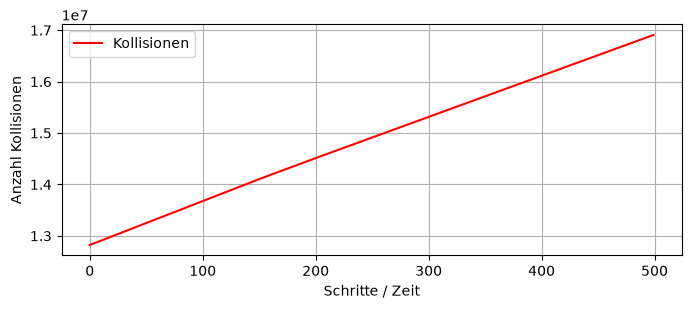

In [ ]:
# # Live-Modus für Matplotlib einschalten
# plt.ion()

# # Initialisiere die Listen für das Diagramm
# steps = []
# collision_data = []

# # Erstelle das Diagramm-Fenster
# fig, ax = plt.subplots(figsize=(8, 3))
# line, = ax.plot([], [], 'r-', label="Kollisionen")
# ax.set_xlabel("Schritte / Zeit")
# ax.set_ylabel("Anzahl Kollisionen")
# ax.legend()
# ax.grid(True)

# # Die Schleife führt die Simulation schrittweise aus und füttert das Diagramm
# for step in range(500):  # Du kannst die Anzahl der Schritte anpassen
#     # 1. Simulation einen Schritt weiterführen und zeichnen
#     simulation.update()
#     simulation.draw()
    
#     # 2. Metriken abfragen
#     metrics = simulation.get_current_metrics()
#     steps.append(step)
#     collision_data.append(metrics["collisions"])
    
#     # 3. Diagramm mit den neuen Werten aktualisieren
#     line.set_xdata(steps)
#     line.set_ydata(collision_data)
#     ax.relim()
#     ax.autoscale_view()
    
#     fig.canvas.draw()
#     fig.canvas.flush_events()
    
#     time.sleep(0.002)


In [ ]:
# import inspect
# print(inspect.getsource(simulation.__class__))